
# CHI-SQUARE TEST FOR INDEPENDENCE
# Customer Satisfaction vs Smart Home Device Type

# import required libraries

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
from scipy.stats import chi2

# Display settings
pd.set_option('display.max_columns', None)

# Cretae Dataset

In [3]:
data = pd.DataFrame({
    "Smart Thermostat": [50, 80, 60, 30, 20],
    "Smart Light": [70, 100, 90, 50, 50]
},
index=[
    "Very Satisfied",
    "Satisfied",
    "Neutral",
    "Unsatisfied",
    "Very Unsatisfied"
])

print("Observed Frequency Table")
display(data)

Observed Frequency Table


,Smart Thermostat,Smart Light
Very Satisfied,50,70
Satisfied,80,100
Neutral,60,90
Unsatisfied,30,50
Very Unsatisfied,20,50


# Dataset Information

In [4]:
print("Shape :", data.shape)
print("\nRows :", data.index.tolist())
print("\nColumns :", data.columns.tolist())

Shape : (5, 2)

Rows : ['Very Satisfied', 'Satisfied', 'Neutral', 'Unsatisfied', 'Very Unsatisfied']

Columns : ['Smart Thermostat', 'Smart Light']


# Visualization - Heatmap

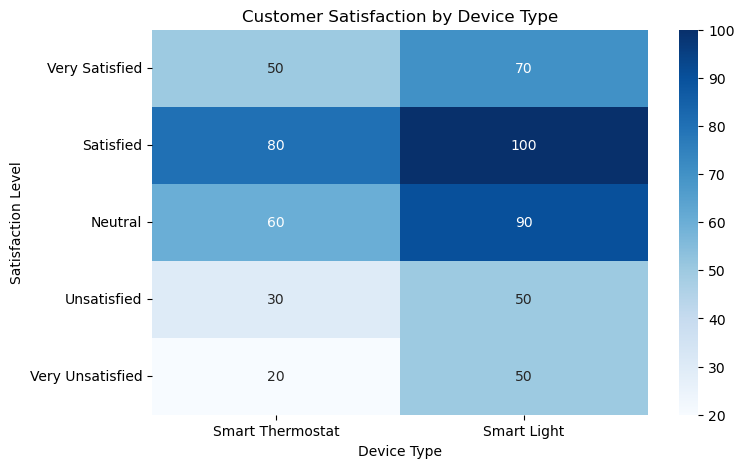

In [5]:
plt.figure(figsize=(8,5))

sns.heatmap(
    data,
    annot=True,
    cmap="Blues",
    fmt="d"
)

plt.title("Customer Satisfaction by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Satisfaction Level")

plt.show()

# Visualization - Bar Plot

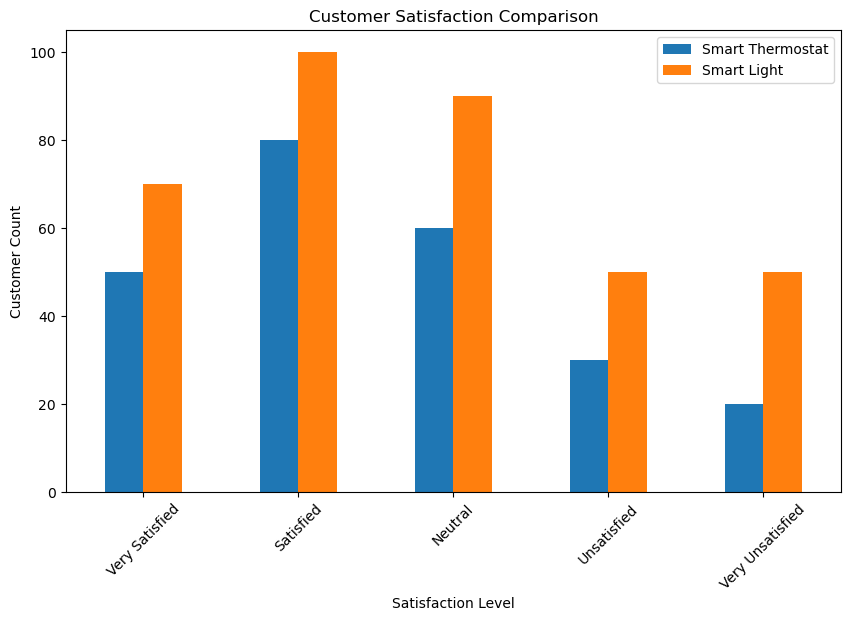

In [27]:
data.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title("Customer Satisfaction Comparison")
plt.xlabel("Satisfaction Level")
plt.ylabel("Customer Count")

plt.xticks(rotation=45)

plt.show()

# Hypopthesis Statement

In [7]:
print("NULL HYPOTHESIS (H0)")
print("Customer Satisfaction and Device Type are Independent")

print("\nALTERNATIVE HYPOTHESIS (H1)")
print("Customer Satisfaction and Device Type are Associated")

NULL HYPOTHESIS (H0)
Customer Satisfaction and Device Type are Independent

ALTERNATIVE HYPOTHESIS (H1)
Customer Satisfaction and Device Type are Associated


# calculate Totals

In [8]:
row_totals = data.sum(axis=1)

column_totals = data.sum(axis=0)

grand_total = data.values.sum()

print("Row Totals")
display(row_totals)

print("\nColumn Totals")
display(column_totals)

print("\nGrand Total =", grand_total)

Row Totals


Very Satisfied      120
Satisfied           180
Neutral             150
Unsatisfied          80
Very Unsatisfied     70
dtype: int64


Column Totals


Smart Thermostat    240
Smart Light         360
dtype: int64


Grand Total = 600


# CHi - Square Test

In [9]:
chi_square_statistic, p_value, dof, expected = chi2_contingency(data)

print("Chi-Square Statistic =", round(chi_square_statistic,4))
print("P-Value =", p_value)
print("Degrees of Freedom =", dof)

Chi-Square Statistic = 5.6382
P-Value = 0.22784371130697179
Degrees of Freedom = 4


# Expected Frequencies

In [10]:
expected_df = pd.DataFrame(
    expected,
    index=data.index,
    columns=data.columns
)

print("Expected Frequencies")

display(expected_df.round(2))

Expected Frequencies


,Smart Thermostat,Smart Light
Very Satisfied,48.0,72.0
Satisfied,72.0,108.0
Neutral,60.0,90.0
Unsatisfied,32.0,48.0
Very Unsatisfied,28.0,42.0


# Visualize - Expected Frequencies

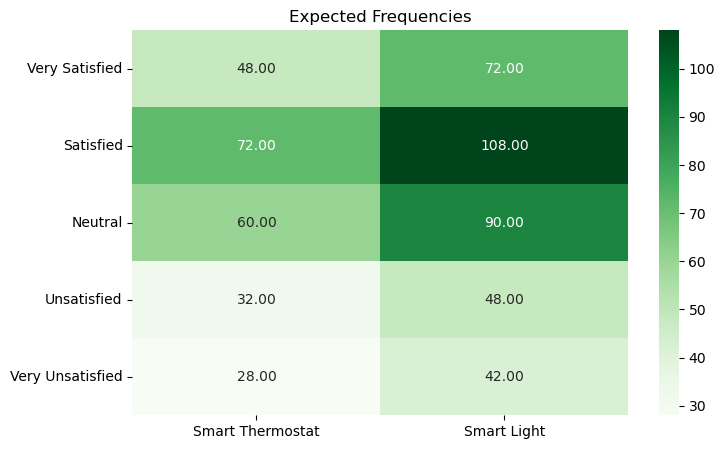

In [11]:
plt.figure(figsize=(8,5))

sns.heatmap(
    expected_df,
    annot=True,
    cmap="Greens",
    fmt=".2f"
)

plt.title("Expected Frequencies")
plt.show()

# Manual Chi-Square Calculation Table

In [30]:
manual_calc = ((data - expected_df)**2) / expected_df

print("Contribution of each cell to Chi-Square Statistic")

display(manual_calc.round(4))

Contribution of each cell to Chi-Square Statistic


,Smart Thermostat,Smart Light
Very Satisfied,0.0833,0.0556
Satisfied,0.8889,0.5926
Neutral,0.0000,0.0000
Unsatisfied,0.1250,0.0833
Very Unsatisfied,2.2857,1.5238


# Verify Manual CH-Square Statistic

In [31]:
manual_chi_square = manual_calc.sum().sum()

print("Manual Chi-Square =", round(manual_chi_square,4))
print("Scipy Chi-Square =", round(chi_square_statistic,4))

Manual Chi-Square = 5.6382
Scipy Chi-Square = 5.6382


# Calculate Critical Value

In [14]:
alpha = 0.05

critical_value = chi2.ppf(
    1-alpha,
    dof
)

print("Significance Level =", alpha)
print("Critical Value =", round(critical_value,4))

Significance Level = 0.05
Critical Value = 9.4877


# Decision Using Critical Value

In [15]:
if chi_square_statistic > critical_value:
    
    print("Decision : Reject H0")
    
else:
    
    print("Decision : Fail to Reject H0")

Decision : Fail to Reject H0


# Decision Using P Value

In [16]:
if p_value < alpha:
    
    print("Decision : Reject H0")
    print("There is a Significant Relationship")
    
else:
    
    print("Decision : Fail to Reject H0")
    print("No Significant Relationship Found")

Decision : Fail to Reject H0
No Significant Relationship Found


# Percentage Distribution

In [18]:
percentage_table = round(
    data / grand_total * 100,
    2
)

percentage_table

,Smart Thermostat,Smart Light
Very Satisfied,8.33,11.67
Satisfied,13.33,16.67
Neutral,10.00,15.00
Unsatisfied,5.00,8.33
Very Unsatisfied,3.33,8.33


# Stacked Percentage Chart

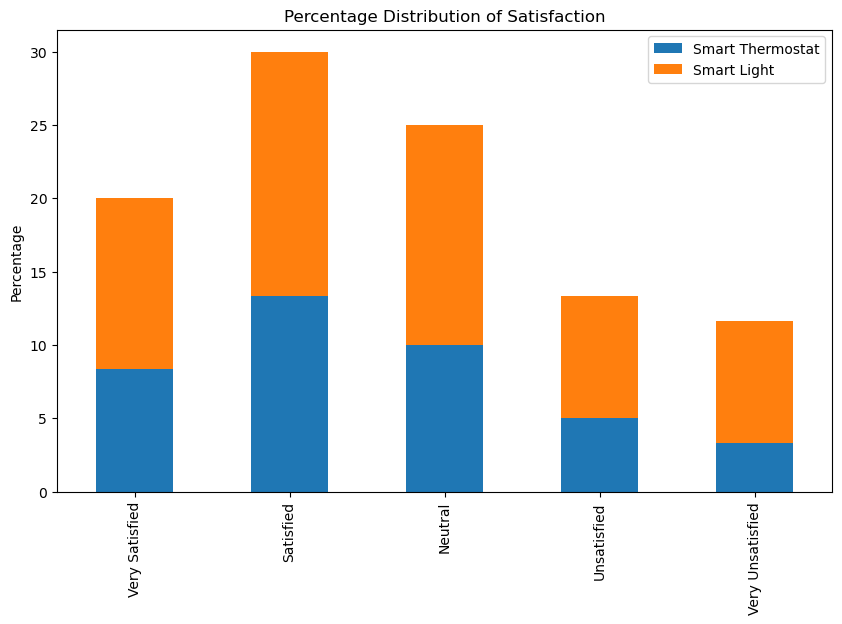

In [32]:
percentage_table.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6)
)

plt.title("Percentage Distribution of Satisfaction")
plt.ylabel("Percentage")

plt.show()


# Business Insights

In [21]:
print("""
BUSINESS INSIGHTS

1. Smart Light has the highest customer count.

2. The majority of customers are either
   Satisfied or Very Satisfied.

3. Very Unsatisfied customers are higher
   for Smart Light compared to Smart Thermostat.

4. Chi-Square Test determines whether
   these differences are statistically significant.

5. Business can use these findings
   to improve customer experience and product quality.
""")


BUSINESS INSIGHTS

1. Smart Light has the highest customer count.

2. The majority of customers are either
   Satisfied or Very Satisfied.

3. Very Unsatisfied customers are higher
   for Smart Light compared to Smart Thermostat.

4. Chi-Square Test determines whether
   these differences are statistically significant.

5. Business can use these findings
   to improve customer experience and product quality.



# Final Conclusion

In [22]:
print("="*60)
print("FINAL CONCLUSION")
print("="*60)

print(f"Chi-Square Statistic : {chi_square_statistic:.4f}")
print(f"P-Value : {p_value:.6f}")
print(f"Critical Value : {critical_value:.4f}")
print(f"Degrees of Freedom : {dof}")

if p_value < alpha:
    
    print("\nCONCLUSION:")
    print("Reject the Null Hypothesis.")
    print("Customer Satisfaction and Device Type are Associated.")
    
else:
    
    print("\nCONCLUSION:")
    print("Fail to Reject the Null Hypothesis.")
    print("Customer Satisfaction and Device Type are Independent.")

FINAL CONCLUSION
Chi-Square Statistic : 5.6382
P-Value : 0.227844
Critical Value : 9.4877
Degrees of Freedom : 4

CONCLUSION:
Fail to Reject the Null Hypothesis.
Customer Satisfaction and Device Type are Independent.


# Viva Questions

In [23]:
viva_questions = [
    "What is the Chi-Square Test?",
    "When is the Chi-Square Test used?",
    "What are the assumptions of the Chi-Square Test?",
    "What is Degrees of Freedom?",
    "What is Expected Frequency?",
    "What does a p-value indicate?",
    "What is the significance level?",
    "How do you interpret Chi-Square results?"
]

for i, question in enumerate(viva_questions, start=1):
    print(f"{i}. {question}")

1. What is the Chi-Square Test?
2. When is the Chi-Square Test used?
3. What are the assumptions of the Chi-Square Test?
4. What is Degrees of Freedom?
5. What is Expected Frequency?
6. What does a p-value indicate?
7. What is the significance level?
8. How do you interpret Chi-Square results?
